In [ ]:
# !pip3 install roboflow ultralytics
# paste here your code snippet from roboflow

#!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="ktuMZGwN1jUBl7jeUrgE")
project = rf.workspace("adam-persson-student-howest-be").project("trash-gaenz")
version = project.version(1)
dataset = version.download("yolo26")
                
                

  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
s3fs 2025.10.0 requires fsspec==2025.10.0, but you have fsspec 2026.3.0 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Trash-1 in yolo26:: 100%|██████████| 3297/3297 [00:00<00:00, 16948.92it/s]


### Train model locally

In [1]:
from ultralytics import YOLO

def main():
    model = YOLO(model="yolo26n.pt")
    # model.train(data="path to your data.yaml file", epochs=25, imgsz=640, verbose=True, batch=8)
    model.train(data="./Trash-1/data.yaml", epochs=5, imgsz=640, verbose=True, batch=8)
    model.val()
    model.export()
if __name__ == '__main__':
    main()

New https://pypi.org/project/ultralytics/8.4.57 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.41 🚀 Python-3.13.9 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3070 Laptop GPU, 7842MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./Trash-1/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale

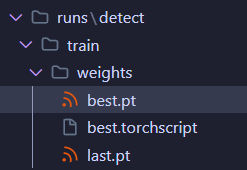

### Load model

In [ ]:
import os
from os import path
print(os.getcwd())

In [2]:
# Load your trained model
model = YOLO("runs/detect/train-2/weights/best.pt")

### Prediction
Default ultralytics visualization.<br>
The output can look different depending if your model originates from roboflow or is trained locally.


image 1/1 /home/adam/Documents/Howest/Project 1/final_project/2025-26-projectone-ctai-Fjanten1/Laptop/test.jpeg: 384x640 (no detections), 7.6ms
Speed: 1.2ms preprocess, 7.6ms inference, 0.2ms postprocess per image at shape (1, 3, 384, 640)


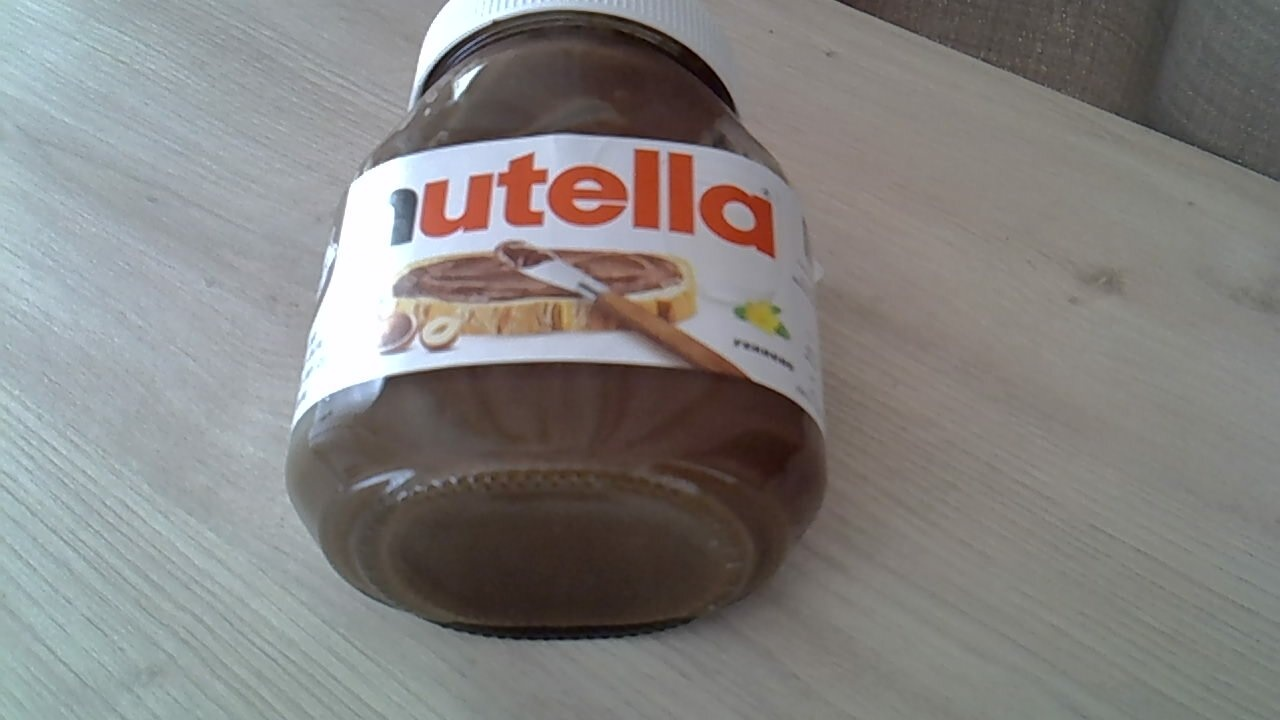

In [10]:
# Make a prediction

path = "test.jpeg" 
result = model.predict(path)
result = result[0] if isinstance(result, list) else result
result.save("prediction_default.jpg")

from IPython.display import Image
Image("prediction_default.jpg")

### Count the instances from a class

In [ ]:
# !pip3 install supervision
import supervision as sv

print(model.names)
def get_keys_from_value(d, val):
    return [k for k, v in d.items() if v == val]

detections = sv.Detections.from_ultralytics(result)
detections = detections[detections.class_id == get_keys_from_value(model.names, 'Drone')] # if necessary replace by your own class
print("Amount of drones: ",len(detections))

### Create a simple interface with gradio
https://www.gradio.app/

In [ ]:
# !pip install gradio
import PIL.Image as Image
import gradio as gr

from ultralytics import ASSETS

def predict_image(img, conf_threshold, iou_threshold):
    results = model.predict(
        source=img,
        conf=conf_threshold,
        iou=iou_threshold,
        show_labels=True,
        show_conf=True,
        imgsz=640,
        agnostic_nms=True
    )

    for r in results:
        im_array = r.plot()
        im = Image.fromarray(im_array[..., ::-1])

    result = model.predict(img)
    result = result[0] if isinstance(result, list) else result 
    detections = sv.Detections.from_ultralytics(result)
    detections = detections[detections.class_id == get_keys_from_value(model.names, 'Drone')]

    print(results)
    return im, {len(detections)}


iface = gr.Interface(
    fn=predict_image,
    inputs=[
        gr.Image(type="pil", label="Upload Image"),
        gr.Slider(minimum=0, maximum=1, value=0.25, label="Confidence threshold"),
        gr.Slider(minimum=0, maximum=1, value=0.45, label="IoU threshold")
    ],
    outputs=[gr.Image(type="pil", label="Result"), gr.Textbox(label="Amount of drones")],
    title="Ultralytics Gradio",
    description="Upload images for inference. The Ultralytics YOLOv8n model is used by default.",
    theme = gr.themes.Monochrome()

)

if __name__ == '__main__':
    iface.launch()